# Домашнее задание: выравнивания и филогенетические деревья (Biopython)

In [ ]:
# @title 📦 1. Установка библиотек (≈1–2 мин). Если Colab попросит перезапустить сессию — нажмите «Restart» и запустите ячейки дальше
%pip install -q biopython ete3 bioservices "scanpy[leiden]" six

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


In [ ]:
# @title ⚙️ 2. Настройки и помощники
# Режим данных:
#   "auto"      — пробуем реальный источник, при ошибке/таймауте берём сгенерированные данные
#   "synthetic" — сразу сгенерированные данные (без интернета, всё работает из РФ)
#   "real"      — только реальные данные (ошибка, если сервис недоступен)
DATA_MODE = "auto"  # @param ["auto", "synthetic", "real"]
TIMEOUT_SEC = 40  # @param {type:"integer"}

import io, re, socket, threading, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

#1
warnings.filterwarnings("ignore", category=SyntaxWarning)   # ete3 шумит
# на новых Python
warnings.filterwarnings("ignore", category=FutureWarning)

#2
socket.setdefaulttimeout(TIMEOUT_SEC)   # чтобы скачивания не висели бесконечно

#3
# ete3 3.1.3 при импорте делает `import cgi`, а в Python ≥ 3.13 модуля cgi
# нет.
# Для работы с деревьями он не нужен, поэтому подставляем пустую заглушку.
import sys, types
try:
    import cgi  # noqa: F401
except ModuleNotFoundError:
    sys.modules["cgi"] = types.ModuleType("cgi")

# --- единый стиль графиков
PAPER, INK, TEAL, TERRA, GOLD = "#F5F0E6", "#1F2D33", "#1F7A8C", "#D9653B", "#E0A526"
PALETTE = ["#1F7A8C", "#D9653B", "#E0A526", "#5B4B8A", "#3E9E6B", "#C2457A", "#7FA7C9", "#8C6D46"]
plt.rcParams.update({
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=PALETTE), "figure.dpi": 100, "font.size": 11,
})

SOURCES = {}   # какие данные реально использованы в каждом блоке


def _run_with_timeout(fn, timeout):
    box = {}
    def target():
        try:
            box["res"] = fn()
        except BaseException as e:          # noqa
            box["err"] = e
    th = threading.Thread(target=target, daemon=True)
    th.start(); th.join(timeout)
    if th.is_alive():
        raise TimeoutError(f"нет ответа за {timeout} с")
    if "err" in box:
        raise box["err"]
    return box["res"]


def get_data(name, real_fn, synth_fn, timeout=None):
    """Пробует real_fn(); если не вышло — synth_fn(). Печатает, что использовано."""
    timeout = timeout or TIMEOUT_SEC
    if DATA_MODE != "synthetic":
        t0 = time.time()
        try:
            res = _run_with_timeout(real_fn, timeout)
            SOURCES[name] = "🌐 реальные"
            print(f"🌐 {name}: реальные данные ({time.time() - t0:.1f} с)")
            return res
        except Exception as e:
            if DATA_MODE == "real":
                raise
            print(f"⚠️  {name}: источник недоступен ({type(e).__name__}: {str(e)[:100]})")
    SOURCES[name] = "🧪 сгенерированные"
    print(f"🧪 {name}: использую сгенерированные данные")
    return synth_fn()


SERVICES = {
    "NCBI Entrez (Biopython)": "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/einfo.fcgi",
    "NCBI Taxonomy (ete3)": "https://ftp.ncbi.nih.gov/pub/taxonomy/",
    "UniProt (bioservices)": "https://rest.uniprot.org/uniprotkb/P04637.fasta",
    "KEGG (bioservices)": "https://rest.kegg.jp/info/hsa",
    "10x Genomics (scanpy, PBMC 3k)": "https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/",
}

#4
def check_services():
    rows = []
    for name, url in SERVICES.items():
        t0 = time.time()
        try:
            r = requests.get(url, timeout=6, stream=True)
            ok, info = r.status_code < 400, f"HTTP {r.status_code}"
        except Exception as e:
            ok, info = False, type(e).__name__
        rows.append({"сервис": name, "доступен": "✅" if ok else "❌",
                     "ответ": info, "время, с": round(time.time() - t0, 1)})
    return pd.DataFrame(rows)

print("Режим данных:", DATA_MODE)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Режим данных: auto


In [ ]:
# @title 🧪 3. Генераторы синтетических данных (можно не раскрывать)
"""Генераторы синтетических данных для лекции (без зависимостей от Bio/ete3/scanpy).
Используются в ноутбуке как запасной вариант, если внешние сервисы недоступны.
"""
import re
import numpy as np
import pandas as pd
from scipy import sparse

# ---------------------------------------------------------------- 1. ген / GenBank
CODONS = [a + b + c for a in "ACGT" for b in "ACGT" for c in "ACGT"]
STOPS = {"TAA", "TAG", "TGA"}
SENSE = [c for c in CODONS if c not in STOPS]


def make_synthetic_gene(n_codons=120, utr5=60, utr3=90, seed=42):
    """Возвращает dict: последовательность мРНК-подобной ДНК + координаты CDS (0-based, end exclusive)."""
    rng = np.random.default_rng(seed)
    five = "".join(rng.choice(list("ACGT"), utr5))
    cds = "ATG" + "".join(rng.choice(SENSE, n_codons - 2)) + "TAA"
    three = "".join(rng.choice(list("ACGT"), utr3)) + "A" * 25  # поли-А хвост
    seq = five + cds + three
    return {"id": "DEMO_000001", "name": "DEMOG1",
            "description": "Synthetic demo gene 1 (generated for teaching)",
            "seq": seq, "cds_start": utr5, "cds_end": utr5 + len(cds)}


# ---------------------------------------------------------------- 2. филогения
TRUE_TREE = ("(((Human:0.04,Chimp:0.05):0.08,Gorilla:0.11):0.15,"
             "((Mouse:0.09,Rat:0.10):0.20,Rabbit:0.22):0.06,"
             "(Chicken:0.30,(Frog:0.35,Zebrafish:0.42):0.10):0.12);")


def parse_newick(nw):
    """Минимальный парсер Newick -> вложенные dict {name, length, children}."""
    nw = nw.strip().rstrip(";")
    pos = 0

    def node():
        nonlocal pos
        n = {"name": "", "length": 0.0, "children": []}
        if nw[pos] == "(":
            pos += 1
            while True:
                n["children"].append(node())
                if nw[pos] == ",":
                    pos += 1
                    continue
                pos += 1  # ')'
                break
        m = re.match(r"([^:,();]*)(?::([0-9.eE+-]+))?", nw[pos:])
        n["name"] = m.group(1)
        n["length"] = float(m.group(2)) if m.group(2) else 0.0
        pos += m.end()
        return n

    return node()


def simulate_alignment(newick=TRUE_TREE, length=600, seed=7):
    """Симуляция эволюции по модели Jukes-Cantor вдоль дерева. Возвращает {имя: последовательность}."""
    rng = np.random.default_rng(seed)
    bases = np.array(list("ACGT"))
    root = parse_newick(newick)
    out = {}

    def evolve(n, seq):
        b = n["length"]
        p = 0.75 * (1 - np.exp(-4 * b / 3))
        mut = rng.random(length) < p
        shift = rng.integers(1, 4, length)
        idx = np.searchsorted(bases, seq)
        new = np.where(mut, (idx + shift) % 4, idx)
        s = bases[new]
        if not n["children"]:
            out[n["name"]] = "".join(s)
        for ch in n["children"]:
            evolve(ch, s)

    anc = rng.choice(bases, length)
    root["length"] = 0.0
    evolve(root, anc)
    return out


# ---------------------------------------------------------------- 3. bioservices fallback
UNIPROT_DEMO = pd.DataFrame({
    "Entry": ["P04637", "Q00987", "P38936", "Q07812", "Q13315", "O96017", "P38398", "P01106"],
    "Entry Name": ["P53_HUMAN", "MDM2_HUMAN", "CDN1A_HUMAN", "BAX_HUMAN", "ATM_HUMAN",
                   "CHK2_HUMAN", "BRCA1_HUMAN", "MYC_HUMAN"],
    "Gene Names": ["TP53 P53", "MDM2", "CDKN1A CAP20 CDKN1 CIP1 MDA6 PIC1 SDI1 WAF1",
                   "BAX BCL2L4", "ATM", "CHEK2 CDS1 CHK2 RAD53", "BRCA1 RNF53", "MYC BHLHE39"],
    "Length": [393, 491, 164, 192, 3056, 543, 1863, 439],
    "Organism": ["Homo sapiens (Human)"] * 8,
})

KEGG_DEMO_PATHWAYS = {
    "hsa04115": "p53 signaling pathway",
    "hsa04110": "Cell cycle",
    "hsa04210": "Apoptosis",
    "hsa04218": "Cellular senescence",
    "hsa05200": "Pathways in cancer",
    "hsa05210": "Colorectal cancer",
    "hsa05212": "Pancreatic cancer",
    "hsa05214": "Glioma",
}

# упрощённая схема p53-сети (для картинки и домашки)
P53_EDGES = [("ATM", "CHEK2"), ("ATM", "TP53"), ("CHEK2", "TP53"), ("MDM2", "TP53"),
             ("TP53", "MDM2"), ("TP53", "CDKN1A"), ("TP53", "BAX"), ("TP53", "GADD45A"),
             ("CDKN1A", "CDK2"), ("BAX", "CYCS"), ("CYCS", "CASP9"), ("CASP9", "CASP3"),
             ("MYC", "TP53"), ("BRCA1", "TP53")]


# ---------------------------------------------------------------- 4. scRNA-seq PBMC-подобные данные
CELL_TYPES = {
    #  тип            доля   маркеры
    "CD4 T":        (0.34, ["CD3E", "CD3D", "IL7R", "CCR7", "LDHB"]),
    "CD8 T":        (0.12, ["CD3E", "CD3D", "CD8A", "CD8B", "GZMK"]),
    "B":            (0.14, ["MS4A1", "CD79A", "CD79B", "BANK1"]),
    "CD14 Mono":    (0.19, ["CD14", "LYZ", "S100A8", "S100A9", "CST3"]),
    "FCGR3A Mono":  (0.07, ["FCGR3A", "MS4A7", "LST1", "CST3"]),
    "NK":           (0.09, ["NKG7", "GNLY", "GZMB", "PRF1"]),
    "DC":           (0.03, ["FCER1A", "CST3", "CLEC10A"]),
    "Platelet":     (0.02, ["PPBP", "PF4"]),
}
MT_GENES = ["MT-CO1", "MT-CO2", "MT-CO3", "MT-ND1", "MT-ND2", "MT-ND4", "MT-ND5",
            "MT-CYB", "MT-ATP6", "MT-ATP8", "MT-ND3", "MT-ND4L", "MT-ND6"]
HOUSEKEEPING = ["ACTB", "GAPDH", "B2M", "MALAT1", "TMSB4X", "EEF1A1",
                "RPL13", "RPS27", "RPL10", "RPS12", "RPL3", "RPS6"]


def make_synthetic_pbmc(n_cells=2700, n_filler=1800, frac_bad=0.06, seed=0):
    """Синтетическая матрица счетов, похожая на PBMC 3k.

    Возвращает (X: csr_matrix cells x genes, obs: DataFrame, var_names: list).
    obs['true_type'] — «правильный ответ», который в реальных данных неизвестен.
    """
    rng = np.random.default_rng(seed)
    markers = sorted({g for _, ms in CELL_TYPES.values() for g in ms})
    filler = [f"GENE{i:04d}" for i in range(1, n_filler + 1)]
    genes = markers + HOUSEKEEPING + MT_GENES + filler
    G = len(genes)
    gidx = {g: i for i, g in enumerate(genes)}

    # базовая доля каждого гена в транскриптоме (логнормальное распределение)
    base = rng.lognormal(mean=-1.0, sigma=1.4, size=G)
    for g in HOUSEKEEPING:
        base[gidx[g]] *= 40
    for g in markers:
        base[gidx[g]] *= 0.15          # маркеры почти не экспрессируются «по умолчанию»
    for g in MT_GENES:
        base[gidx[g]] *= 3

    types = list(CELL_TYPES)
    probs = np.array([CELL_TYPES[t][0] for t in types])
    probs /= probs.sum()
    labels = rng.choice(types, size=n_cells, p=probs)

    # профиль каждого типа: маркеры x 25-60, плюс немного «индивидуальности» у филлеров
    # профиль типа = базовый профиль × маркеры × «программа линии» (T-клетки и моноциты родственны)
    lineage = {"T": rng.lognormal(0, 0.18, n_filler), "Mono": rng.lognormal(0, 0.18, n_filler)}
    lin_of = {"CD4 T": "T", "CD8 T": "T", "NK": "T", "CD14 Mono": "Mono",
              "FCGR3A Mono": "Mono", "DC": "Mono"}
    f0 = len(markers) + len(HOUSEKEEPING) + len(MT_GENES)
    profiles = {}
    for t in types:
        p = base.copy()
        for g in CELL_TYPES[t][1]:
            p[gidx[g]] *= rng.uniform(10, 30)
        p[f0:] *= rng.lognormal(0, 0.2, n_filler) * lineage.get(lin_of.get(t), 1.0)
        profiles[t] = p / p.sum()

    lib = rng.lognormal(mean=np.log(2200), sigma=0.45, size=n_cells)
    bad = rng.random(n_cells) < frac_bad          # «умирающие» клетки: мало РНК, много MT
    lib[bad] *= rng.uniform(0.15, 0.4, bad.sum())

    mt_idx = np.array([gidx[g] for g in MT_GENES])
    rows, cols, vals = [], [], []
    disp = 0.4                                        # отрицательное биномиальное: r = 1/disp
    for c in range(n_cells):
        p = profiles[labels[c]].copy()
        if bad[c]:
            p[mt_idx] *= rng.uniform(6, 12)
            p /= p.sum()
        mu = p * lib[c]
        lam = rng.gamma(shape=1 / disp, scale=mu * disp)
        cnt = rng.poisson(lam)
        nz = np.nonzero(cnt)[0]
        rows.append(np.full(nz.size, c)); cols.append(nz); vals.append(cnt[nz])
    X = sparse.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
                          shape=(n_cells, G), dtype=np.float32)
    barcodes = ["".join(rng.choice(list("ACGT"), 16)) + "-1" for _ in range(n_cells)]
    obs = pd.DataFrame({"true_type": pd.Categorical(labels, categories=types),
                        "low_quality": bad}, index=barcodes)
    return X, obs, genes


MARKER_GENES = {t: ms for t, (_, ms) in CELL_TYPES.items()}

## Уменьшите length в simulate_alignment до 60. Что стало с деревьями?

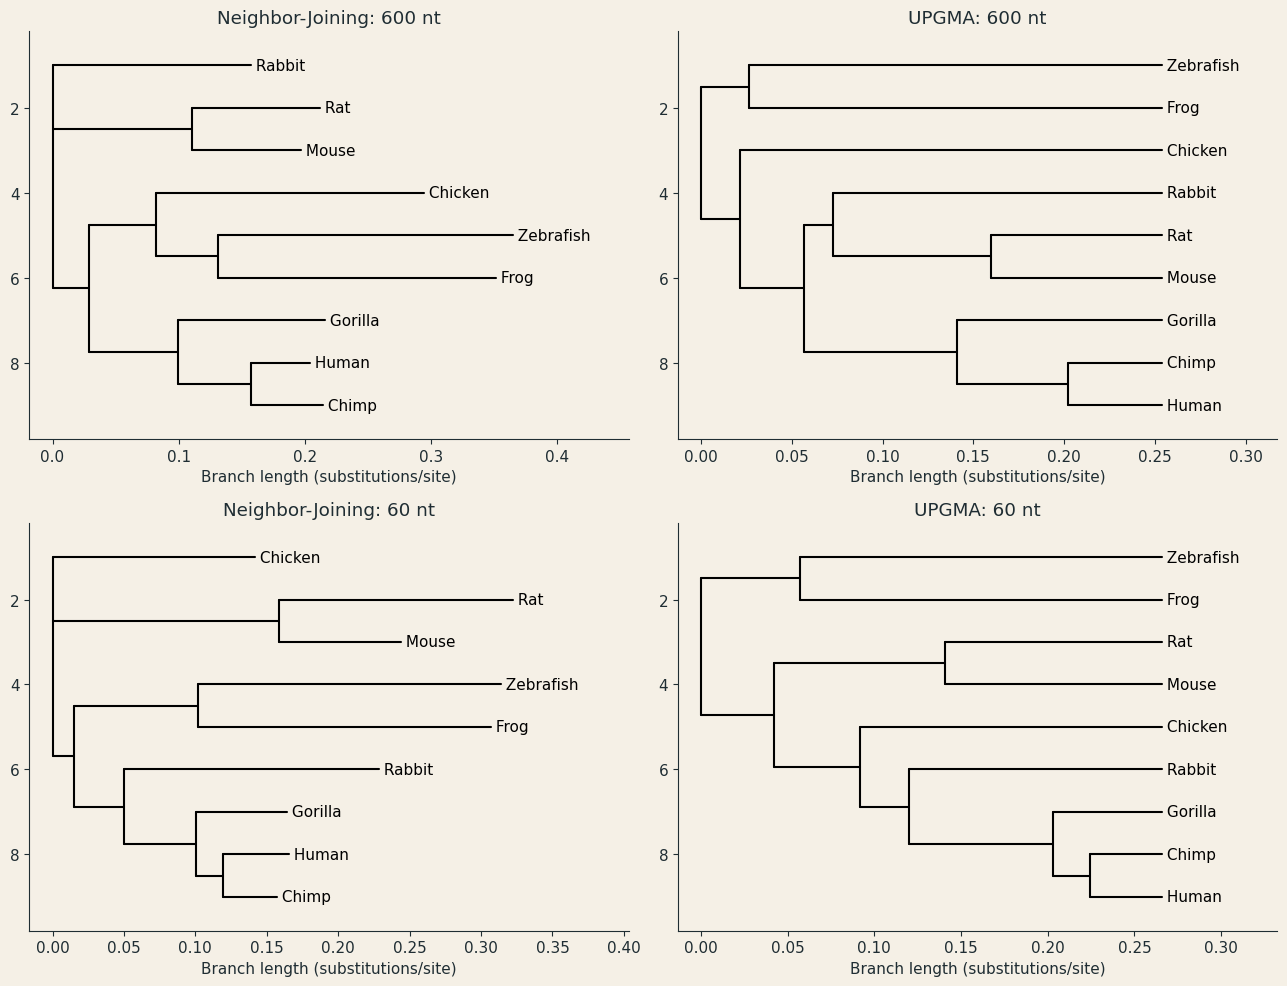

In [5]:
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.Align import MultipleSeqAlignment
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor
from Bio import Phylo
import matplotlib.pyplot as plt

sim_long = simulate_alignment(TRUE_TREE, length=600, seed=7)
sim_short = simulate_alignment(TRUE_TREE, length=60, seed=7)
msa = MultipleSeqAlignment([
    SeqRecord(Seq(seq), id=name) for name, seq in sim_long.items()
])
msa_short = MultipleSeqAlignment([
    SeqRecord(Seq(seq), id=name) for name, seq in sim_short.items()
])

calculator = DistanceCalculator("identity")
constructor = DistanceTreeConstructor()
trees = {}
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, (length, alignment) in enumerate([(600, msa), (60, msa_short)]):
    distances = calculator.get_distance(alignment)
    for col, (method, build) in enumerate([
        ("Neighbor-Joining", constructor.nj), ("UPGMA", constructor.upgma)
    ]):
        tree = build(distances)
        trees[(length, method)] = tree
        tree.ladderize()
        Phylo.draw(
            tree, axes=axes[row, col], do_show=False,
            label_func=lambda clade: clade.name if clade.is_terminal() else ""
        )
        axes[row, col].set_title(f"{method}: {length} nt")
        axes[row, col].set_xlabel("Branch length (substitutions/site)")
        axes[row, col].set_ylabel("")
plt.tight_layout()
plt.show()

**Ответ:** при уменьшении длины выравнивания с 600 до 60 нуклеотидов у обоих методов изменились длины ветвей и группировки последовательностей. Меньшее число позиций усиливает влияние случайных замен на оценку расстояний между последовательностями

## Посчитайте, сколько в msa позиций, где все последовательности одинаковы (консервативные сайты).

In [ ]:
conserved_positions = [
    i + 1
    for i in range(msa.get_alignment_length())
    if len(set(msa[:, i])) == 1
]
n_conserved = len(conserved_positions)
alignment_length = msa.get_alignment_length()
print(f"Число последовательностей: {len(msa)}")
print(f"Длина msa: {alignment_length} нт")
print(f"Консервативных позиций: {n_conserved}")
print(f"Доля консервативных позиций: {n_conserved / alignment_length:.2%}")

Число последовательностей: 9
Длина msa: 600 нт
Консервативных позиций: 58
Доля консервативных позиций: 9.67%


**Ответ:** 58 консервативных позиций (9,67% всех позиций)